<a href="https://colab.research.google.com/github/Fauzi455/PembelajaranMesin_2026/blob/main/JS-07/TUGAS/Tugas%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#TUGAS LAB

1. Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Apakah sebaran data dapat dikatakan linier?

In [1]:
from google.colab import files
uploaded = files.upload()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv


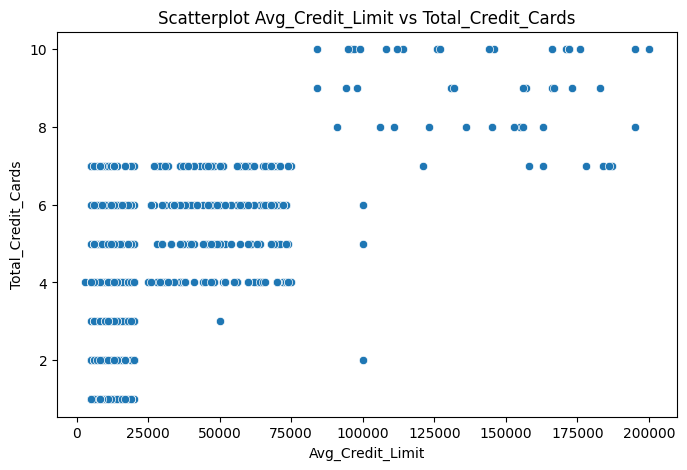

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#memuat dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

#membuat scatterplot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards')
plt.title('Scatterplot Avg_Credit_Limit vs Total_Credit_Cards')
plt.show()

Jawaban Analisis: Sebaran data tidak dapat dikatakan linier. Berdasarkan pola scatterplot, titik-titik data tidak membentuk garis lurus yang menunjukkan korelasi linier positif maupun negatif yang kuat, melainkan cenderung menyebar dan membentuk kelompok-kelompok tertentu pada rentang limit kredit dan jumlah kartu kredit.

2. Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah
k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

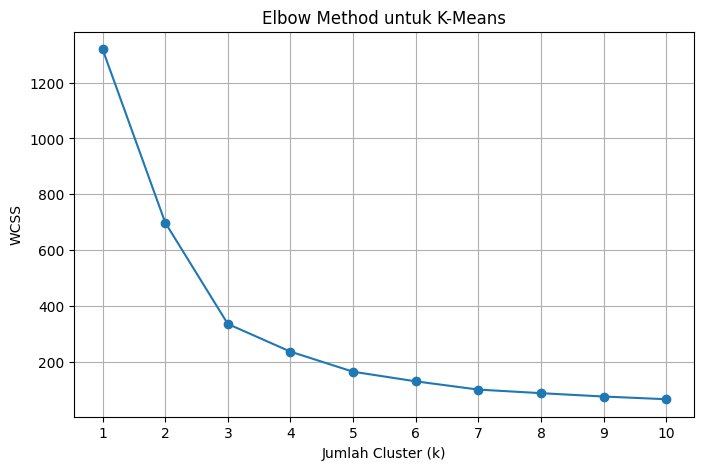

In [13]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

#memilih dua variabel
X_2d = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]

#standarisasi data
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

#menghitung WCSS untuk Elbow Method
wcss = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_2d_scaled)
    wcss.append(kmeans.inertia_)

#membuat Linechart
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o')
plt.title('Elbow Method untuk K-Means')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('WCSS')
plt.xticks(k_range)
plt.grid(True)
plt.show()

3. Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.

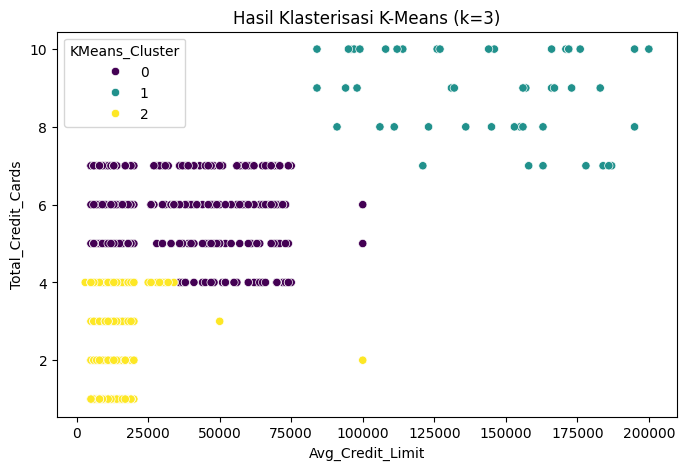

In [15]:
#menerapkan K-Means dengan k optimal
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_2d_scaled)

#menggambarkan scatterplot hasil klasterisasi
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards',
                hue='KMeans_Cluster', palette='viridis')

plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.show()

4. Buatlah model klasterisasi dengan menggunakan DBSCAN dengan seluruh variabel yang dapat digunakan.

In [16]:
from sklearn.cluster import DBSCAN

#menyiapkan seluruh variabel
X_all = df.drop(columns=['Sl_No', 'Customer Key', 'KMeans_Cluster'], errors='ignore')

#standarisasi seluruh fitur
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

5. Tentukan jumlah k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

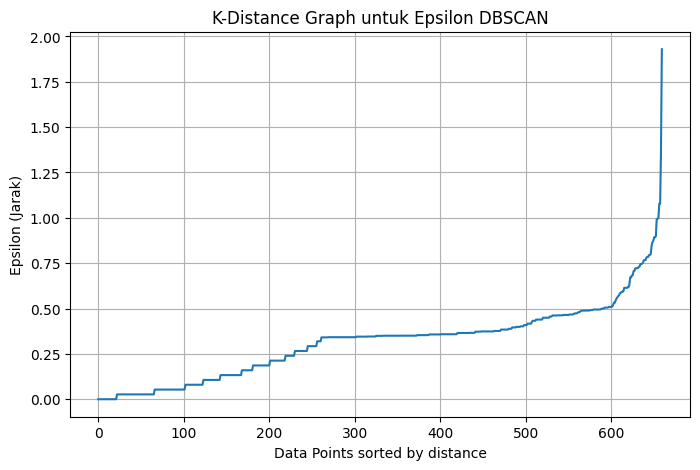

In [19]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

#menentukan min_samples
min_samples = 2 * X_all_scaled.shape[1]

#menghitung jarak ke tetangga terdekat
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_all_scaled)
distances, indices = neighbors_fit.kneighbors(X_all_scaled)

#mengurutkan jarak dan membuat linechart (k-distance graph)
distances = np.sort(distances, axis=0)
distances = distances[:, 1]

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-Distance Graph untuk Epsilon DBSCAN')
plt.xlabel('Data Points sorted by distance')
plt.ylabel('Epsilon (Jarak)')
plt.grid(True)
plt.show()

6. Tentukan nilai silhouette score dan DBI dari model DBSCAN.

In [20]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

#menjalankan DBSCAN dengan eps optimal dari nomor 5 (misal eps=1.0)
eps_optimal = 1.0 # Ganti dengan nilai dari grafik k-distance Anda
dbscan = DBSCAN(eps=eps_optimal, min_samples=min_samples)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_all_scaled)

#mengevaluasi model (Pastikan DBSCAN tidak hanya mendeteksi 1 cluster atau noise saja)
if len(set(df['DBSCAN_Cluster'])) > 1:
    sil_score = silhouette_score(X_all_scaled, df['DBSCAN_Cluster'])
    dbi_score = davies_bouldin_score(X_all_scaled, df['DBSCAN_Cluster'])
    print(f"Silhouette Score DBSCAN: {sil_score:.4f}")
    print(f"Davies-Bouldin Index (DBI) DBSCAN: {dbi_score:.4f}")
else:
    print("Evaluasi gagal: DBSCAN hanya menemukan 1 klaster atau menganggap semua data sebagai noise. Silakan sesuaikan kembali nilai eps.")

Silhouette Score DBSCAN: 0.5569
Davies-Bouldin Index (DBI) DBSCAN: 0.7075
